# --------------------------------------------------------------
# Code for van der Pol Oscillator example: Standard DeepONet architecture
# --------------------------------------------------------------
## This notebook includes:
 - Input signal generation (multisine)
 - Simulation of van der Pol Dynamics and data generation 
 - DeepONet prediction model learning using pytorch
 - Model Predictive Control (MPC) simulation using CasADi
# --------------------------------------------------------------

### Import required packages 

In [ ]:
# Standard libraries
import time
import itertools
import sys

# Scientific computing
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.io import savemat

# Plotting
import matplotlib.pyplot as plt

# Deep learning
import torch
import torch.nn.functional as F
import models  # custom model module

# Optimization (solving the MPC problem)
import casadi as ca

# Functions used in scripts
from functions import van_der_pol, NN, multisine 
 

### Generate input signal used for model learning 

(2410,)
(2410,)


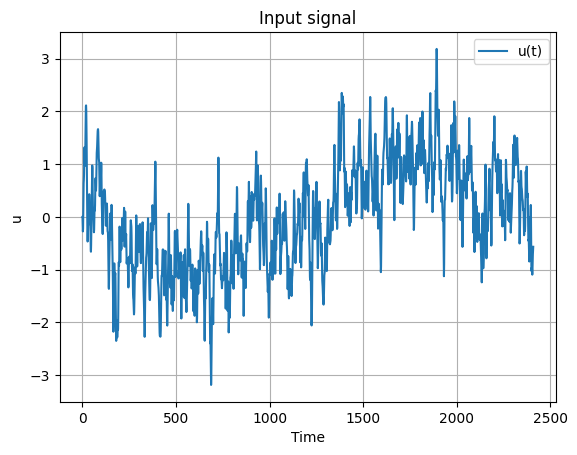

In [16]:
# Length of input signal 
T_period = 2410 

# Generate multisine using custom multisine function from functions.py
u_data = 2*multisine(N_points_per_period=T_period, N_periods=1, pmin=1, pmax=500, n_crest_factor_optim=100,seed=42)

# Generate a single sine 
x = np.linspace(-np.pi, np.pi, T_period)

# Add the multisine to the single sine wave
u_data = u_data + np.sin(x)

# Filter the input signal trough a low pass filter
print(u_data.shape)
u_filtered = np.zeros(len(u_data))
print(u_filtered.shape)
for i in range(0,len(u_data)-1):
    u_filtered[i+1] = 0.9*u_filtered[i] + 0.1*u_data[i]


# Plot the final input signal which will be used to generate the data
plt.plot(u_filtered, label='u(t)')
plt.title('Input signal')
plt.xlabel('Time')
plt.ylabel('u')
plt.legend()
plt.grid()
plt.show()

### Generate output data for the van der Pol Oscillator, used for training

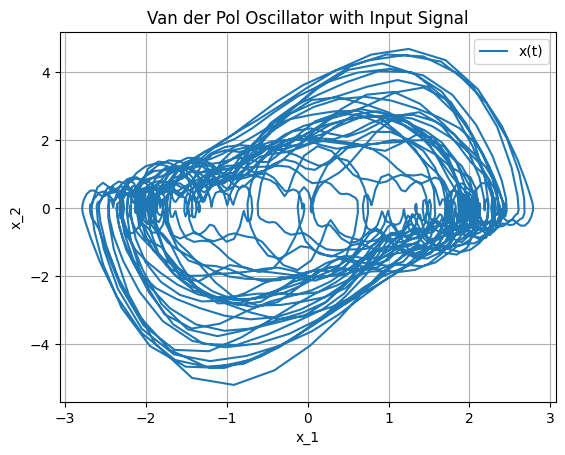

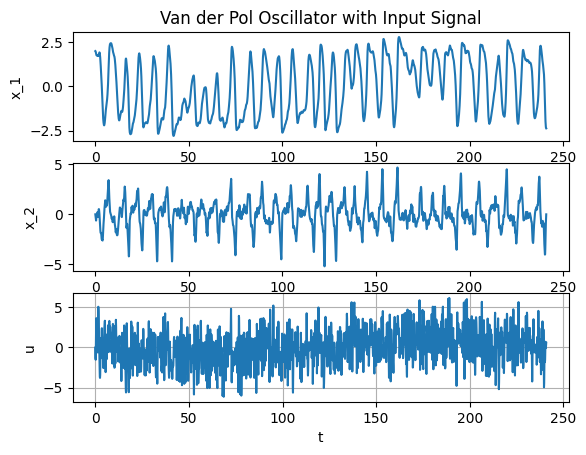

In [17]:
# Parameters
N = 10 # prediction horizon of the controller
Ts = 0.1 # Sampling time of the controller
mu = 1.0  # You can change this value to see different behaviors of the van der Pol oscillator
y0 = [2, 0]  # Initial conditions: [x0, dx0]

t_vec = [0]
x = [y0]

# Main loop
for i in range(len(u_data)):
    u = u_data[i]
    # Simulate van de Pol Oscillator for 1 sampling period
    sol = solve_ivp(lambda t, y: van_der_pol(t, y, mu, u),[0, Ts], y0, method='RK45')

    # Take the last value as the new initial condition
    y0 = sol.y[:, -1]
    x.append(y0)  # store state
    t_vec.append((i+1) * Ts)  # store time

# Convert list to numpy array for easier plotting
x = np.array(x)
t_vec = np.array(t_vec)

# Plotting
plt.plot(x[:, 0], x[:, 1], label='x(t)')
plt.title('Van der Pol Oscillator with Input Signal')
plt.xlabel('x_1')
plt.ylabel('x_2')
plt.legend()
plt.grid()
plt.show()

# Plotting
plt.subplot(3,1,1)
plt.plot(t_vec, x[:, 0], label='$x_1$')
plt.title('Van der Pol Oscillator with Input Signal')
plt.ylabel('x_1')
plt.xlabel('t')
plt.subplot(3,1,2)
plt.plot(t_vec, x[:, 1], label='x_2')
plt.ylabel('x_2')
plt.xlabel('t')
plt.subplot(3,1,3)
plt.plot(t_vec[:-1], u_data, label='x_2')
plt.ylabel('u')
plt.xlabel('t')
plt.grid()
plt.show()



### Generate data matrices used for model learning

In [18]:
# Initialze empty data matrices
Z = [] # Initial condition + time z = [x0,t] data matrix
Y = [] # Output data matrix
U = [] # Input data matrix

# For loop for generating Hankel matrices
for i in range(len(x[:,0])-N):
    for j in range(N):
        Y.append([x[i + j+1,0]]) #  Append Y with output data
        Z.append(list(x[i, :]) + [(j + 1)*Ts]) # Append Z with initial condition and time data
        U.append(u_data[i:i+N]) #  Append U with input data

# Convert to numpy arrays 
Y = np.array(Y)
Z = np.array(Z)
U = np.array(U)

# Divide data into training and validation (2001*N samples for training)
U_train = U[0:20010,:]
U_val = U[20010:,:]
Z_train = Z[0:20010,:]
Z_val = Z[20010:,:]
Y_train = Y[0:20010,:]
Y_val = Y[20010:,:]

# Optional: print shapes
print("Shapes after split:")
print(f"U_train: {U_train.shape}, U_val: {U_val.shape}")
print(f"X0_train: {Z_train.shape}, Z_val: {Z_val.shape}")
print(f"Y_train: {Y_train.shape}, Y_val: {Y_val.shape}")

Shapes after split:
U_train: (20010, 10), U_val: (4000, 10)
X0_train: (20010, 3), Z_val: (4000, 3)
Y_train: (20010, 1), Y_val: (4000, 1)


### Train the standard DeepONet model 

In [10]:
# Define the network dimensions
ld_list = [20] # Neurons in output layer, change to [20,30,...] to train for multiple combinations
neuron_list = [40] # Neurons per hidden layer, change to [20,30,...] to train for multiple combinations
layer_list = [3] # number of hidden layers, change to [2,3,...] to train for multiple combinations
N_epoch = 40000 # Number of epochs used for training the model
N_comb = len(ld_list)*len(neuron_list)*len(layer_list) # Total number of hyperparameter configurations to train for

# make sure that GPU is used when available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Convert training data to tensors
trunk_input_train = torch.tensor(Z_train, dtype=torch.float32).to(device)
branch_input_train = torch.tensor(U_train, dtype=torch.float32).to(device)
output_train = torch.squeeze(torch.tensor(Y_train, dtype=torch.float32).to(device))

# Convert validation data to tensors
trunk_input_val = torch.tensor(Z_val, dtype=torch.float32).to(device)
branch_input_val = torch.tensor(U_val, dtype=torch.float32).to(device)
output_val = torch.squeeze(torch.tensor(Y_val, dtype=torch.float32).to(device))

# Network and data dimensions
B_train = len(trunk_input_train[:,0]) # Batch size for training data
B_val = len(trunk_input_val[:,0]) # Batch size for validation data
nx = len(trunk_input_train[0,:]) # Input dimension Trunk net
Nnu = len(branch_input_train[0,:]) # Input dimension Branch net
ny = 1 # Output dimension network

# Define the network using pytorch 
def train(idx,neuron,layer,ld,loss_val_i, niter):
    # Define the Branch network:
    branch = models.MLP(
        layers=[Nnu] + [neuron] * layer + [ld*ny],
        activation=F.tanh,
    ).to(device)

    # Define the Trunk network:
    trunk = models.MLP(layers=[nx] + [neuron] * layer + [ld], activation=F.tanh).to(device)

    # Define the optimizer, learning rate, weight decay
    optimizer = torch.optim.AdamW(
        list(branch.parameters()) + list(trunk.parameters()), 
        lr=1e-3,
        weight_decay=1e-4  # L2 regularization (weight decay)
    )

    # Add a learning rate scheduler that reduces the learning rate by a factor of gamma every step_size iterations
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10000, gamma=0.1)

    # Initialize empty list for storing the training and validation loss
    train_loss_hist = []
    val_loss_hist = []
    t0 = time.time()
    # training loop
    for i in range(niter):
        # Training step
        def train_step():
            optimizer.zero_grad() # reset the gradients    
            # Forward pass:               
            b_out = branch(branch_input_train) # Branch net forward pass
            t_out = trunk(trunk_input_train) # Trunk net forward pass
            u_pred = torch.einsum("bj,bj->b", b_out, t_out) # Product layer
            loss = torch.mean((u_pred - output_train) ** 2) / torch.mean((output_train) ** 2) # Calculate training loss 
            # Backward pass: 
            loss.backward() 
            # Update parameters:
            optimizer.step() 
            return loss
        
        # Validation step
        def validation_step():
             with torch.no_grad():               
                b_out = branch(branch_input_val)
                t_out = trunk(trunk_input_val)
                u_pred = torch.einsum("bj,bj->b", b_out, t_out)
                loss = torch.mean((u_pred - output_val) ** 2) / torch.mean((output_val) ** 2)
                return loss

        loss_train = train_step() # Perform a training step (includes forward pass, loss calc, backward pass, optimizer step)
        loss_val = validation_step() # Perform a validation step (forward pass + loss calc, no weight updates)
        l_train = loss_train.detach().cpu().numpy() # Move training loss tensor to CPU, detach from graph, convert to NumPy
        l_val = loss_val.detach().cpu().numpy() # Same as above for validation loss


        train_loss_hist.append(l_train) # Append training loss data 
        val_loss_hist.append(l_val) # Append validation loss data 

        current_lr = optimizer.param_groups[0]['lr'] # Get the current learning rate from the optimizer
        current_lr = round(current_lr, 5) # Round the learning rate to 5 decimal places for printing
        
        # Print usefull information during training:
        if i % 10 == 0:
            print(
                "index: ",
                idx,
                "/ ",
                N_comb,
                "Epoch: ",
                i + 1,
                "Learning rate: ",
                current_lr,
                "Train loss",
                l_train,
                "Val loss",
                l_val,
                flush=True,
            )
        # Save the model every 100 iterations and only when validation loss has decreased
        if i % 100 == 0 and loss_val_i >= l_val:
            loss_val_i = l_val
            l_indx_i = i
            torch.save(branch, "data_standard/kan_mlp_branch_idx_{}".format(str(int(idx))))
            torch.save(trunk, "data_standard/kan_mlp_trunk_idx_{}".format(str(int(idx))))

        # Step the scheduler at the end of each iteration
        scheduler.step()
        
    t1 = time.time()
    print("Total time: ", t1 - t0, flush=True)
    t_elapsed = t1 - t0

    # Save training and validation losses
    np.save("data_standard/train_loss.npy", train_loss_hist, allow_pickle=True)
    np.save("data_standard/val_loss.npy", val_loss_hist, allow_pickle=True)

    return np.array(train_loss_hist), np.array(val_loss_hist), l_indx_i, loss_val_i, t_elapsed


# start of the ablation study 
ablation_results = [] # Initialize empty list for storing the ablation results 
combinations = itertools.product(ld_list,neuron_list,layer_list) # Generate set of hyperparameter configurations for ablation study 
idx_i = 0 # Initialize training index 

# Looping through the range of indices 
for ld_i, neuron_i, layer_i in combinations:
    idx_i += 1
    # Call the train function with the current index
    train_loss_hist_i, val_loss_hist_i, l_indx_opt, loss_val_opt, t_elapsed   = train(idx=idx_i,ld=ld_i,neuron=neuron_i,layer=layer_i,loss_val_i=float('inf'),niter=N_epoch)
    
    # Create a dictionary to store the results
    results = {
        'idx': idx_i,
        'neurons output layer': ld_i,
        'neurons hidden per layer': neuron_i,
        'hidden layers': layer_i,
        'training loss': train_loss_hist_i,
        'validation loss': val_loss_hist_i,
        'training time': t_elapsed
    }
    
    # Append the results to the ablation_results list
    ablation_results.append(results)


Using device: cpu
index:  1 /  1 Epoch:  1 Learning rate:  0.001 Train loss 1.0544968 Val loss 0.9968826
index:  1 /  1 Epoch:  11 Learning rate:  0.001 Train loss 0.46342483 Val loss 0.38976523
index:  1 /  1 Epoch:  21 Learning rate:  0.001 Train loss 0.14913392 Val loss 0.2205059
index:  1 /  1 Epoch:  31 Learning rate:  0.001 Train loss 0.0849766 Val loss 0.10163631
index:  1 /  1 Epoch:  41 Learning rate:  0.001 Train loss 0.07189607 Val loss 0.09308491
index:  1 /  1 Epoch:  51 Learning rate:  0.001 Train loss 0.06685832 Val loss 0.086797364
index:  1 /  1 Epoch:  61 Learning rate:  0.001 Train loss 0.06473763 Val loss 0.08208397
index:  1 /  1 Epoch:  71 Learning rate:  0.001 Train loss 0.06258856 Val loss 0.08288287
index:  1 /  1 Epoch:  81 Learning rate:  0.001 Train loss 0.060401518 Val loss 0.07861211
index:  1 /  1 Epoch:  91 Learning rate:  0.001 Train loss 0.05831138 Val loss 0.07752495
index:  1 /  1 Epoch:  101 Learning rate:  0.001 Train loss 0.0561566 Val loss 0.0745

### Convert the ablation results to a .mat file for analysis with MATLAB

Text(0.5, 1.0, 'Training and validation loss')

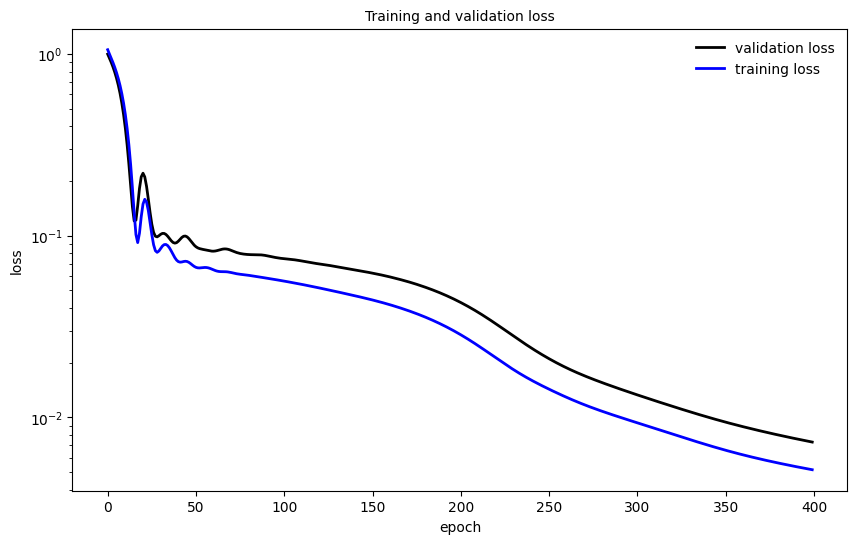

In [19]:
# Prepare dictionary for saving in .mat format
ablation_mat = {}

# Flatten the ablation_results list into a structured dict
for i, result in enumerate(ablation_results):
    ablation_mat[f'result_{i}'] = {
        'idx': result['idx'],
        'neurons_output_layer': result['neurons output layer'],
        'neurons_hidden_per_layer': result['neurons hidden per layer'],
        'hidden_layers': result['hidden layers'],
        'train_loss': np.array(result['training loss']),
        'val_loss': np.array(result['validation loss']),
        'T_train': np.array(result['training time'])
    }

# Save the structured dict to a .mat file
savemat("data_standard/ablation_results.mat", ablation_mat)

# Make figure
plt.figure(figsize=(10, 6))
for i in range(len(ablation_mat)):
    plt.subplot(len(ablation_mat), 1, i+1) 
    plt.semilogy(ablation_mat[f'result_{i}']['val_loss'], '-k', lw=2.0, label="validation loss")
    plt.semilogy(ablation_mat[f'result_{i}']['train_loss'], '-b', lw=2.0, label="training loss")
    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.legend(frameon=False, loc = 'best')
    
plt.title('Training and validation loss', fontsize = 10)    


### Perform standard DeepONet based MPC simulation

<>:114: SyntaxWarning: invalid escape sequence '\d'
<>:114: SyntaxWarning: invalid escape sequence '\d'
C:\Users\20183249\AppData\Local\Temp\ipykernel_14968\3289205073.py:114: SyntaxWarning: invalid escape sequence '\d'
  plt.plot(t_vec, x_vals[:, 1], label='$\dot{x}$')


i = 0 / 150
U[0] = opti1_x_2[0]
i = 1 / 150
U[0] = opti1_x_2[0]
i = 2 / 150
U[0] = opti1_x_2[0]
i = 3 / 150
U[0] = opti1_x_2[0]
i = 4 / 150
U[0] = opti1_x_2[0]
i = 5 / 150
U[0] = opti1_x_2[0]
i = 6 / 150
U[0] = opti1_x_2[0]
i = 7 / 150
U[0] = opti1_x_2[0]
i = 8 / 150
U[0] = opti1_x_2[0]
i = 9 / 150
U[0] = opti1_x_2[0]
i = 10 / 150
U[0] = opti1_x_2[0]
i = 11 / 150
U[0] = opti1_x_2[0]
i = 12 / 150
U[0] = opti1_x_2[0]
i = 13 / 150
U[0] = opti1_x_2[0]
i = 14 / 150
U[0] = opti1_x_2[0]
i = 15 / 150
U[0] = opti1_x_2[0]
i = 16 / 150
U[0] = opti1_x_2[0]
i = 17 / 150
U[0] = opti1_x_2[0]
i = 18 / 150
U[0] = opti1_x_2[0]
i = 19 / 150
U[0] = opti1_x_2[0]
i = 20 / 150
U[0] = opti1_x_2[0]
i = 21 / 150
U[0] = opti1_x_2[0]
i = 22 / 150
U[0] = opti1_x_2[0]
i = 23 / 150
U[0] = opti1_x_2[0]
i = 24 / 150
U[0] = opti1_x_2[0]
i = 25 / 150
U[0] = opti1_x_2[0]
i = 26 / 150
U[0] = opti1_x_2[0]
i = 27 / 150
U[0] = opti1_x_2[0]
i = 28 / 150
U[0] = opti1_x_2[0]
i = 29 / 150
U[0] = opti1_x_2[0]
i = 30 / 150
U[0] = 

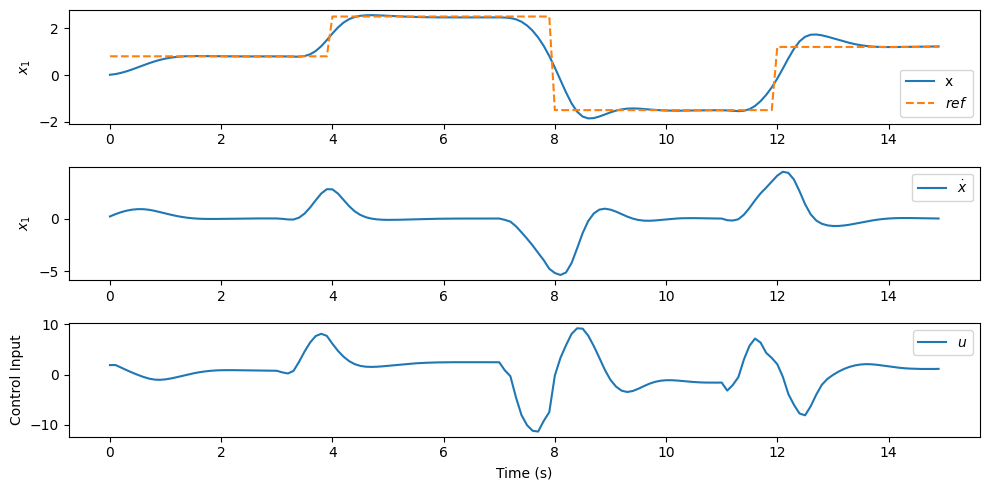

In [ ]:
# select optimal index based on the minimal validation loss in ablation_results:
idx_opt = 1 # change to correct index as defined in the code block: Train the standard DeepONet model 
branch = torch.load("data_standard/kan_mlp_branch_idx_{}".format(str(int(idx_opt))), map_location=torch.device('cpu'), weights_only=False)
trunk = torch.load("data_standard/kan_mlp_trunk_idx_{}".format(str(int(idx_opt))), map_location=torch.device('cpu'), weights_only=False)

# Van der Pol Oscillator parameters
ld_list = 20 # Select here correct number of neurons in output layer of model with index idx_opt

# System dimensions van der
nx = 2  # [theta, theta_dot]
ny = 1  # [theta]
nu = 1  # u

# MPC cost function matrices
Q = np.eye(N) * 100
R = np.eye(N * nu)

# Define constant pieces for reference signal
ref1 = np.tile([0.8], (40, 1))    
ref2 = np.tile([2.5], (40, 1))   
ref3 = np.tile([-1.5], (40, 1))     
ref4 = np.tile([1.2], (40, 1))   

# Concatenate them along the first axis (time steps)
xref_traj = np.concatenate((ref1, ref2, ref3,ref4), axis=0)  

# Set up optimization problem
opti = ca.Opti()
y = opti.variable(ny*N,)
u = opti.variable(nu*N,)
du = opti.variable(nu*N,)
x0 = opti.parameter(nx)
z = opti.parameter(nx+1)
u0 = opti.parameter(nu)
ref = opti.parameter(ny*N,)

# Define cost function
cost = ca.mtimes([(y-ref).T, Q, (y-ref)]) + ca.mtimes([du.T, R, du])

# Neural network predictions
b_out = NN(u, branch, np.tanh)
# loop over t = 1T_s, 2T_s, ..., NT_s
for i in range(N):
    z = ca.vertcat(x0, (i+1)*Ts) 
    t_out = NN(z, trunk, np.tanh) 
    opti.subject_to(y[i] == b_out.T@t_out)  # output prediction

# Define constrains for the MPC problem
opti.subject_to(du[0:nu] == u[0:nu] - u0) # Define \delta u(0)
opti.subject_to(du[nu:] == u[nu:] - u[:-nu])  # Define  \delta u

# Define optimization problem
opti.minimize(cost)

# Solver options
opti.solver('ipopt', {'ipopt.print_level': 0, 'print_time': 0})

x_vals = [] # Initialize empty list for storing state data
u_vals = [] # Initialize empty list for storing input data
solve_times = []  # Initialize empty list to store time per control action 

x_current = np.array([0.0, 0.0])  # Initial conditions for van de Pol oscillator
u_mpc = 0 # Initial condition for inut (needed for \delta u(0))

# Warm start for input sequence at k=0
previous_u_guess = np.zeros(N)
previous_du_guess = np.zeros(N)

# Start of the simulation loop
for i in range(len(xref_traj)-N):
    print(f'i = {i} / {len(xref_traj)-N}')
    REF = xref_traj[i:i+N,:].T
    opti.set_value(x0, x_current)
    opti.set_value(u0, u_mpc)
    opti.set_value(ref, REF)

    # Initial guess for the solver
    opti.set_initial(u, previous_u_guess)
    opti.set_initial(du, previous_du_guess)

    start = time.perf_counter()
    sol = opti.solve()
    elapsed = time.perf_counter() - start
    solve_times.append(elapsed)  # Store each solve time

    previous_u_guess = sol.value(u)
    previous_u_guess = np.concatenate([previous_u_guess[1:], previous_u_guess[-1:]])
    previous_du_guess = sol.value(du)
    previous_du_guess = np.concatenate([previous_du_guess[1:], previous_du_guess[-1:]])

    print(f'U[0] = {u[0]}')
    u_mpc = sol.value(u[0])
    
    sol = solve_ivp(lambda t, y: van_der_pol(t, y, mu, u_mpc),[0, Ts], x_current, method='RK45')

    # Take the last value as the new initial condition
    x_next = sol.y[:, -1] # measured state at t = (i+1)T_s
    x_vals.append(x_next) # Append state data vector
    u_vals.append(u_mpc) # Append input data vector
    x_current = x_next # Initialize new current state for next iteration

solve_times = np.array(solve_times) # Convert control times to numpy array 
x_vals = np.array(x_vals) # Convert state data to numpy array 
u_vals = np.array(u_vals) # Convert input data to numpy array 
t_vec = np.arange(len(xref_traj)-N) * Ts # Define time vector

# Make figure of the closed--loop response
plt.figure(figsize=(10, 5))
plt.subplot(3, 1, 1)
plt.plot(t_vec, x_vals[:, 0], label='x')
plt.plot(t_vec, xref_traj[:-N], label='$ref$',linestyle = '--')
plt.ylabel("$x_1$")
plt.legend()

plt.subplot(3, 1, 2)
plt.plot(t_vec, x_vals[:, 1], label='$\dot{x}$')
plt.ylabel("$x_1$")
plt.legend()

plt.subplot(3, 1, 3)
plt.plot(t_vec, u_vals, label='$u$')
plt.xlabel("Time (s)")
plt.ylabel("Control Input")
plt.legend()

plt.tight_layout()
plt.show()


## save MPC results a .mat files for analysis in Matlab

In [21]:
# Put them in a dictionary with variable names
data_to_save = {
    "x_vals_st": x_vals,
    "u_vals_st": u_vals,
    "solve_times_st": solve_times,
    "xref_traj_st": xref_traj    
}

# Save to a .mat file
savemat('data_standard/standard_vdp.mat', data_to_save)
print("Arrays saved to 'standard_vdp.mat'")



Arrays saved to 'standard_vdp.mat'
